PART 1 - IQR, Z-score Visualization

In [2]:
import pandas as pd
import numpy as np

df01 = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120, 150, 180, 200, 220, 240,
              260, 280, 300, 350, 400, 2500],
    "Quantity": [1, 2, 2, 3, 3, 4,
                 4, 5, 5, 6, 7, 40]})

q1_sales = df01['Sales'].quantile(0.25)
q3_sales = df01['Sales'].quantile(0.75)
iqr_sales = q3_sales - q1_sales
lower_bound_sales = q1_sales - 1.5 * iqr_sales
upper_bound_sales = q3_sales + 1.5 * iqr_sales

q1_qty = df01['Quantity'].quantile(0.25)
q3_qty = df01['Quantity'].quantile(0.75)
iqr_qty = q3_qty - q1_qty
lower_bound_qty = q1_qty - 1.5 * iqr_qty
upper_bound_qty = q3_qty + 1.5 * iqr_qty


df01['Sales Outlier'] = (df01['Sales'] < lower_bound_sales) | (df01['Sales'] > upper_bound_sales)
df01['Quantity Outlier'] = (df01['Quantity'] < lower_bound_qty) | (df01['Quantity'] > upper_bound_qty)

df01

,Transaction_ID,Sales,Quantity,Sales Outlier,Quantity Outlier
0,1,120,1,False,False
1,2,150,2,False,False
2,3,180,2,False,False
3,4,200,3,False,False
4,5,220,3,False,False
5,6,240,4,False,False
6,7,260,4,False,False
7,8,280,5,False,False
8,9,300,5,False,False
9,10,350,6,False,False


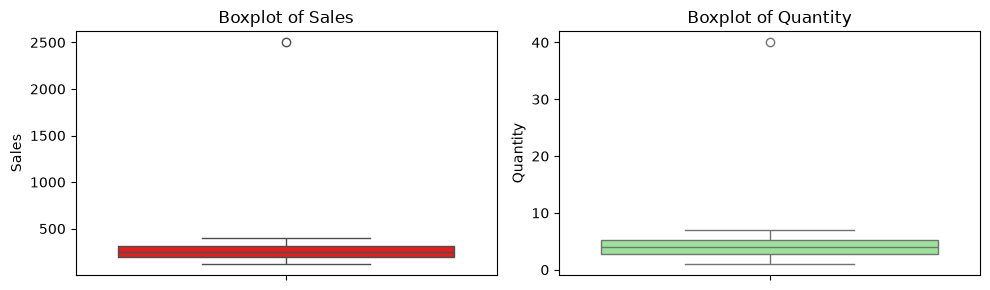

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.boxplot(y=df01['Sales'], ax=axes[0], color='red')
axes[0].set_title('Boxplot of Sales')
axes[0].set_ylabel('Sales')

sns.boxplot(y=df01['Quantity'], ax=axes[1], color='lightgreen')
axes[1].set_title('Boxplot of Quantity')
axes[1].set_ylabel('Quantity')
plt.tight_layout()
plt.show()

In [4]:
from scipy import stats

df02 = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68, 70, 69, 72, 71, 73,
                    70, 74, 68, 72, 71, 115],
    "Pressure": [30, 32, 31, 33, 32, 34,
                 31, 33, 32, 35, 34, 60]
})
df02['Temp_Zscore'] = stats.zscore(df02['Temperature'])
df02['Press_Zscore'] = stats.zscore(df02['Pressure'])
df02['Temp Outlier'] = abs(df02['Temp_Zscore']) > 3
df02['Press Outlier'] = abs(df02['Press_Zscore']) > 3

df02

,Machine_ID,Temperature,Pressure,Temp_Zscore,Press_Zscore,Temp Outlier,Press Outlier
0,1,68,30,-0.518910,-0.613969,False,False
1,2,70,32,-0.357172,-0.355456,False,False
2,3,69,31,-0.438041,-0.484712,False,False
3,4,72,33,-0.195434,-0.226199,False,False
4,5,71,32,-0.276303,-0.355456,False,False
5,6,73,34,-0.114565,-0.096942,False,False
6,7,70,31,-0.357172,-0.484712,False,False
7,8,74,33,-0.033695,-0.226199,False,False
8,9,68,32,-0.518910,-0.355456,False,False
9,10,72,35,-0.195434,0.032314,False,False


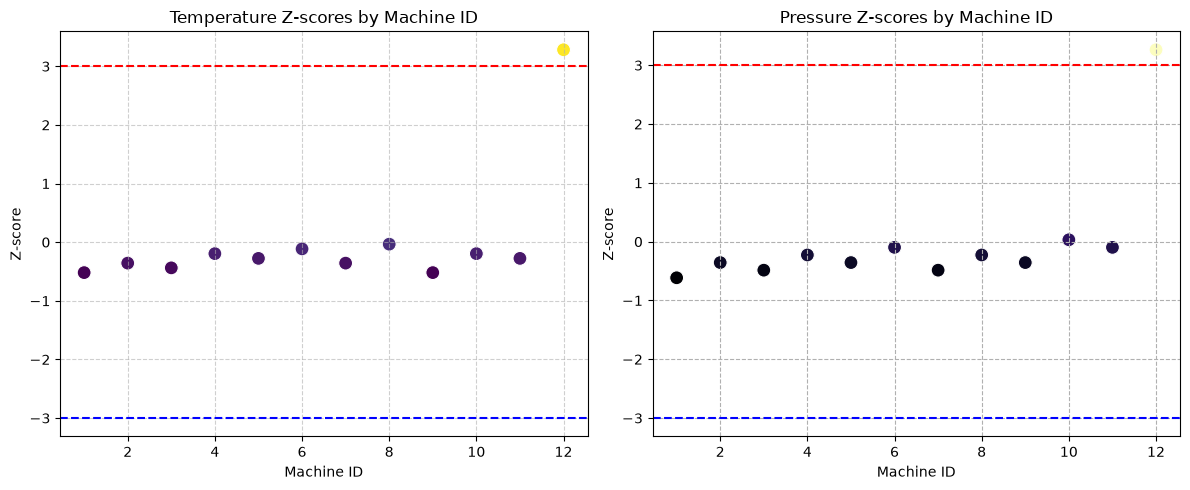

In [5]:
df02['Temp_Zscore'] = stats.zscore(df02['Temperature'])
df02['Press_Zscore'] = stats.zscore(df02['Pressure'])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df02, x='Machine_ID', y='Temp_Zscore', hue='Temp_Zscore',palette='viridis', s=100, ax=axes[0], legend=False)
axes[0].axhline(3, color='red', linestyle='--', label='Threshold (+3)')
axes[0].axhline(-3, color='blue', linestyle='--', label='Threshold (-3)')
axes[0].set_title('Temperature Z-scores by Machine ID')
axes[0].set_xlabel('Machine ID')
axes[0].set_ylabel('Z-score')
axes[0].grid(True, linestyle='--', alpha=0.6)
sns.scatterplot(data=df02, x='Machine_ID', y='Press_Zscore', hue='Press_Zscore',palette='magma',s=100, legend = False)
axes[1].axhline(3, color='red', linestyle='--', label='Threshold (+3)')
axes[1].axhline(-3, color='blue', linestyle='--', label='Threshold (-3)')
axes[1].set_title('Pressure Z-scores by Machine ID')
axes[1].set_xlabel('Machine ID')
axes[1].set_ylabel('Z-score')
axes[1].grid(True, linestyle='--', alpha=1.0)
plt.tight_layout()

plt.show()

In [6]:
from scipy.stats import zscore

df03 = pd.DataFrame({
    "Transaction_Amount": [
        100, 120, 130, 150, 160, 170,
        180, 200, 220, 250, 300, 350,
        400, 450, 500, 800, 1200, 10000 ]})
df03["Z_Score"] = zscore(df03["Transaction_Amount"])
df03["Z_Score_Flag"] = np.abs(df03["Z_Score"]) > 3

q1 = df03["Transaction_Amount"].quantile(0.25)
q3 = df03["Transaction_Amount"].quantile(0.75)
iqr = q1 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df03["IQR_Flag"] = (df03["Transaction_Amount"] < lower_bound) | (df03["Transaction_Amount"] > upper_bound)

df03

,Transaction_Amount,Z_Score,Z_Score_Flag,IQR_Flag
0,100,-0.345721,False,True
1,120,-0.336755,False,True
2,130,-0.332271,False,True
3,150,-0.323304,False,True
4,160,-0.318821,False,True
5,170,-0.314337,False,False
6,180,-0.309854,False,False
7,200,-0.300887,False,False
8,220,-0.291920,False,False
9,250,-0.278470,False,False


In [7]:
df04 = pd.DataFrame({
    "Student_ID": range(1, 13),
    "Study_Hours": [1, 2, 2, 3, 3, 4,
                    4, 5, 5, 6, 7, 50],
    "Exam_Score": [35, 40, 45, 48, 52, 55,
                   60, 65, 68, 72, 78, 100]
})

q1_study_hours = df04['Study_Hours'].quantile(0.25)
q3_study_hours = df04['Study_Hours'].quantile(0.75)
iqr_study_hours = q3_study_hours - q1_study_hours
lower_bound_studyhours = q1_study_hours - 1.5 * iqr_study_hours
upper_bound_studyhours = q3_study_hours + 1.5 * iqr_study_hours

q1_exam_score = df04['Exam_Score'].quantile(0.25)
q3_exam_score = df04['Exam_Score'].quantile(0.75)
iqr_exam_score = q3_exam_score- q1_exam_score
lower_bound_examscores = q1_exam_score - 1.5 * iqr_exam_score
upper_bound_examscores = q3_exam_score + 1.5 * iqr_exam_score

df04['Study_Hours_Z'] = stats.zscore(df04['Study_Hours'])
df04['Exam_Score_Z'] = stats.zscore(df04['Exam_Score'])

df04

,Student_ID,Study_Hours,Exam_Score,Study_Hours_Z,Exam_Score_Z
0,1,1,35,-0.517867,-1.425919
1,2,2,40,-0.440187,-1.138821
2,3,2,45,-0.440187,-0.851723
3,4,3,48,-0.362507,-0.679465
4,5,3,52,-0.362507,-0.449787
5,6,4,55,-0.284827,-0.277528
6,7,4,60,-0.284827,0.009570
7,8,5,65,-0.207147,0.296668
8,9,5,68,-0.207147,0.468926
9,10,6,72,-0.129467,0.698605


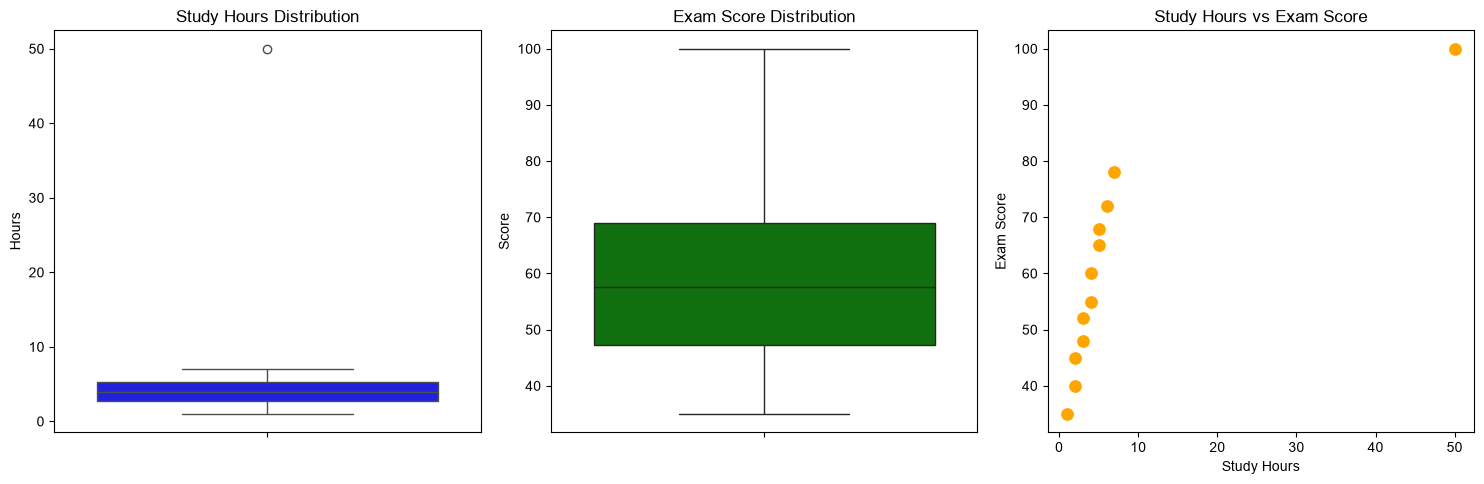

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.set_theme(style="whitegrid")

sns.boxplot(y=df04['Study_Hours'], ax=axes[0], color='blue')
axes[0].set_title('Study Hours Distribution')
axes[0].set_ylabel('Hours')

sns.boxplot(y=df04['Exam_Score'], ax=axes[1], color='green')
axes[1].set_title('Exam Score Distribution')
axes[1].set_ylabel('Score')

sns.scatterplot(x='Study_Hours', y='Exam_Score', data=df04, ax=axes[2], color='orange', s=100)
axes[2].set_title('Study Hours vs Exam Score')
axes[2].set_xlabel('Study Hours')
axes[2].set_ylabel('Exam Score')

plt.tight_layout()
plt.show()

PART 2 -Outlier Removal vs Capping

In [9]:

import pandas as pd

df05 = pd.DataFrame({
    "Employee_ID": range(1, 11),
    "Age": [22, 25, 28, 30, 32, 35, 38, 40, 42, 100],
    "Salary": [25000, 28000, 30000, 32000, 35000,
               38000, 42000, 45000, 50000, 500000]
})

def finding_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    return lb, ub

age_lb, age_ub = finding_outliers(df05, "Age")
sal_lb, sal_ub = finding_outliers(df05, "Salary")
age_outliers = df05[(df05["Age"] < age_lb) | (df05["Age"] > age_ub)]
salary_outliers = df05[(df05["Salary"] < sal_lb) | (df05["Salary"] > sal_ub)]

df_removed = df05[(df05["Age"] >= age_lb) & (df05["Age"] <= age_ub) & (df05["Salary"] >= sal_lb) & (df05["Salary"] <= sal_ub)]
df_capped = df05.copy()
df_capped["Age"] = df_capped["Age"].clip(age_lb, age_ub)
df_capped["Salary"] = df_capped["Salary"].clip(sal_lb, sal_ub)
df06 = pd.concat([age_outliers, salary_outliers, df_removed, df_capped])
df06

,Employee_ID,Age,Salary
9,10,100,500000
9,10,100,500000
0,1,22,25000
1,2,25,28000
2,3,28,30000
3,4,30,32000
4,5,32,35000
5,6,35,38000
6,7,38,42000
7,8,40,45000


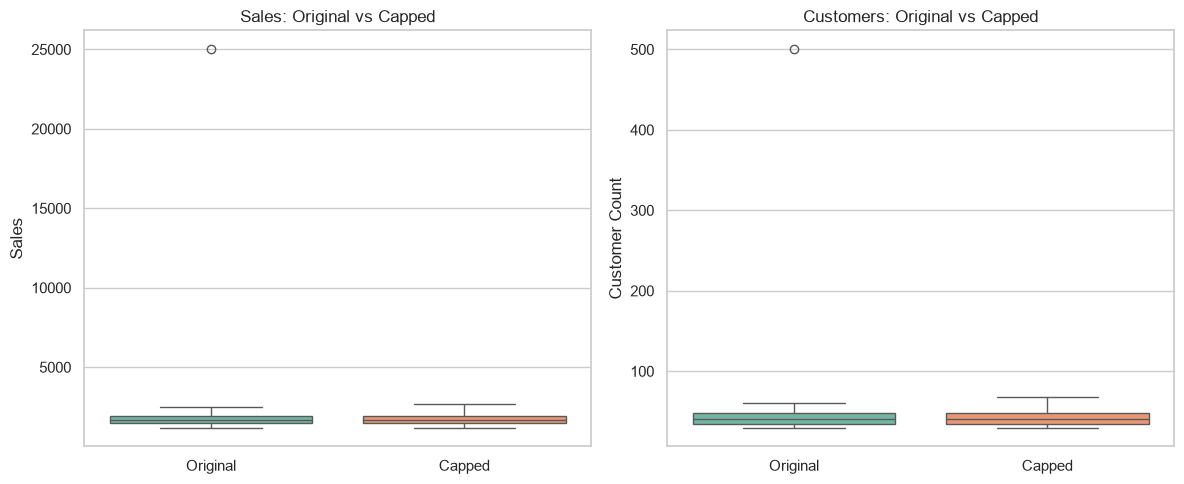

In [10]:
df07 = pd.DataFrame({
    "Day": range(1, 13),
    "Sales": [1200, 1350, 1400, 1500, 1600, 1550,
              1700, 1800, 1900, 2100, 2500, 25000],
    "Customers": [30, 32, 35, 33, 38, 40,
                  42, 45, 47, 50, 60, 500]
})

features = ["Sales", "Customers"]
bounds = {}

def finding_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lb = Q1 - 1.5 * IQR
    ub = Q3 + 1.5 * IQR
    return lb, ub

sales_lb, sales_ub = finding_outliers(df07, "Sales")
customers_lb, customers_ub = finding_outliers(df07, "Customers")
sales_outliers = df07[(df07["Sales"] < sales_lb) | (df07["Sales"] > sales_ub)]
customers_outliers = df07[(df07["Customers"] < customers_lb) | (df07["Customers"] > customers_ub)]

df_removed = df07[(df07["Sales"] >= sales_lb) & (df07["Sales"] <= sales_ub) & (df07["Customers"] >= customers_lb) & (df07["Customers"] <= customers_ub)]
df_capped = df07.copy()
df_capped["Sales"] = df_capped["Sales"].clip(sales_lb,sales_ub)
df_capped["Customers"] = df_capped["Customers"].clip(customers_lb,customers_ub)
df08 = pd.concat([sales_outliers, customers_outliers, df_removed, df_capped])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sales_data = pd.DataFrame({'Original': df07['Sales'],'Capped': df_capped['Sales']})
sns.boxplot(data=sales_data, ax=axes[0], palette="Set2")
axes[0].set_title('Sales: Original vs Capped')
axes[0].set_ylabel('Sales')

customer_data = pd.DataFrame({'Original': df07['Customers'],'Capped': df_capped['Customers']})
sns.boxplot(data=customer_data, ax=axes[1], palette="Set2")
axes[1].set_title('Customers: Original vs Capped')
axes[1].set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

In [22]:
df08 = pd.DataFrame({
"Customer_ID": range(101, 113),
"Annual_Spending": [8000, 10000, 12000, 15000, 18000, 20000,22000, 25000, 30000, 35000, 50000, 800000],
"Order_Count": [2, 3, 3, 4, 5, 5, 6, 7, 8, 9, 12, 100],
"Customer_Segment": ["Basic", "Basic", "Silver", "Silver","Gold", "Basic", "Silver", "Gold","Gold", "Silver", "Premium", "Premium"]
})

annual_spending_lb, annual_spending_ub = finding_outliers(df08, "Annual_Spending")
order_count_lb, order_count_ub = finding_outliers(df08, "Order_Count")
annual_spending_outliers = df08[(df08["Annual_Spending"] < annual_spending_lb) | (df08["Annual_Spending"] > annual_spending_ub)]
order_count_outliers = df08[(df08["Order_Count"] < order_count_lb) | (df08["Order_Count"] > order_count_ub)]

print("annual spending outliers:\n", annual_spending_outliers)
print("---------------------------------------------------------------------------")
print("order count outliers:\n", order_count_outliers)

annual spending outliers:
     Customer_ID  Annual_Spending  Order_Count Customer_Segment
11          112           800000          100          Premium
---------------------------------------------------------------------------
order count outliers:
     Customer_ID  Annual_Spending  Order_Count Customer_Segment
11          112           800000          100          Premium


In [29]:
from IPython.core.display_functions import display
df_removal01 = df08[(df08["Annual_Spending"] <= annual_spending_ub) & (df08["Annual_Spending"] >= annual_spending_lb) &
 (df08["Order_Count"] <= order_count_ub) & (df08["Order_Count"] >= order_count_lb)].copy()
df_capping01 = df08.copy()
df_capping01["Annual_Spending"] = df_capping01["Annual_Spending"].clip(lower=annual_spending_lb,upper=annual_spending_ub)
df_capping01["Order_Count"] = df_capping01["Order_Count"].clip(lower=order_count_lb,upper=order_count_ub)

display(df_removal01)
display(df_capping01)

,Customer_ID,Annual_Spending,Order_Count,Customer_Segment
0,101,8000,2,Basic
1,102,10000,3,Basic
2,103,12000,3,Silver
3,104,15000,4,Silver
4,105,18000,5,Gold
5,106,20000,5,Basic
6,107,22000,6,Silver
7,108,25000,7,Gold
8,109,30000,8,Gold
9,110,35000,9,Silver


,Customer_ID,Annual_Spending,Order_Count,Customer_Segment
0,101,8000,2,Basic
1,102,10000,3,Basic
2,103,12000,3,Silver
3,104,15000,4,Silver
4,105,18000,5,Gold
5,106,20000,5,Basic
6,107,22000,6,Silver
7,108,25000,7,Gold
8,109,30000,8,Gold
9,110,35000,9,Silver


In [30]:
stats = {"Dataset": ["Original", "Removal", "Capped"], "Mean":[df08["Annual_Spending"].mean(),
        df_removal01["Annual_Spending"].mean(),
        df_capping01["Annual_Spending"].mean()],
    "Median": [df08["Annual_Spending"].median(),
        df_removal01["Annual_Spending"].median(),
        df_capping01["Annual_Spending"].median()]}

df_stats = pd.DataFrame(stats)
df_stats

,Dataset,Mean,Median
0,Original,87083.333333,21000.0
1,Removal,22272.727273,20000.0
2,Capped,25145.833333,21000.0
